# 07 - Combined Severe Case (S8)

**Question:** the stress test. High loading, weak actuator authority, measurement noise, fast
drift, and a topology outage are all combined in one run. Does the CRI correctly collapse to
Reject, hold `s_k=0`, keep `kappa_k` low, request digital-twin validation, and let the fallback
controller run the plant safely throughout -- while Direct activation (and even the simple
threshold rule) do not?

Outputs: `results/results_S8.csv`, `Figures/Fig_severe_dashboard.pdf`.

In [2]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from cri_microgrid.config import (PlantParams, ControllerParams, ConstraintParams, CRIParams,
                                   ProbeParams, ProfileParams, SimulationParams)
from cri_microgrid import scenarios, sim, metrics, validation, plotstyle

plotstyle.apply_style()
RESULTS_DIR = os.path.abspath("../results")
FIG_DIR = os.path.abspath("../Figures")
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

pp = PlantParams()
cp = ControllerParams()
cons = ConstraintParams()
crip = CRIParams()
probep = ProbeParams()
prof = ProfileParams()
SEED = 1

In [3]:
scenario = scenarios.build_S8(pp, prof, T_end=50.0)
logs = {}
for strategy in ["direct", "threshold", "cri"]:
    simp = SimulationParams(T_end=scenario.T_end, seed=SEED, strategy=strategy)
    logs[strategy] = sim.run_closed_loop(scenario, pp, cp, cons, crip, probep, simp)
log = logs["cri"]
print(scenario.description)

Combined: high loading + weak authority + noise + fast drift + topology outage.


## Figure 10 -- Severe-case dashboard (CRI-supervised run)

e:\PhD\TSCT_Paper\TSCT_Paper_CRI\TCST_CRI\cri_microgrid\plotstyle.py:51: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


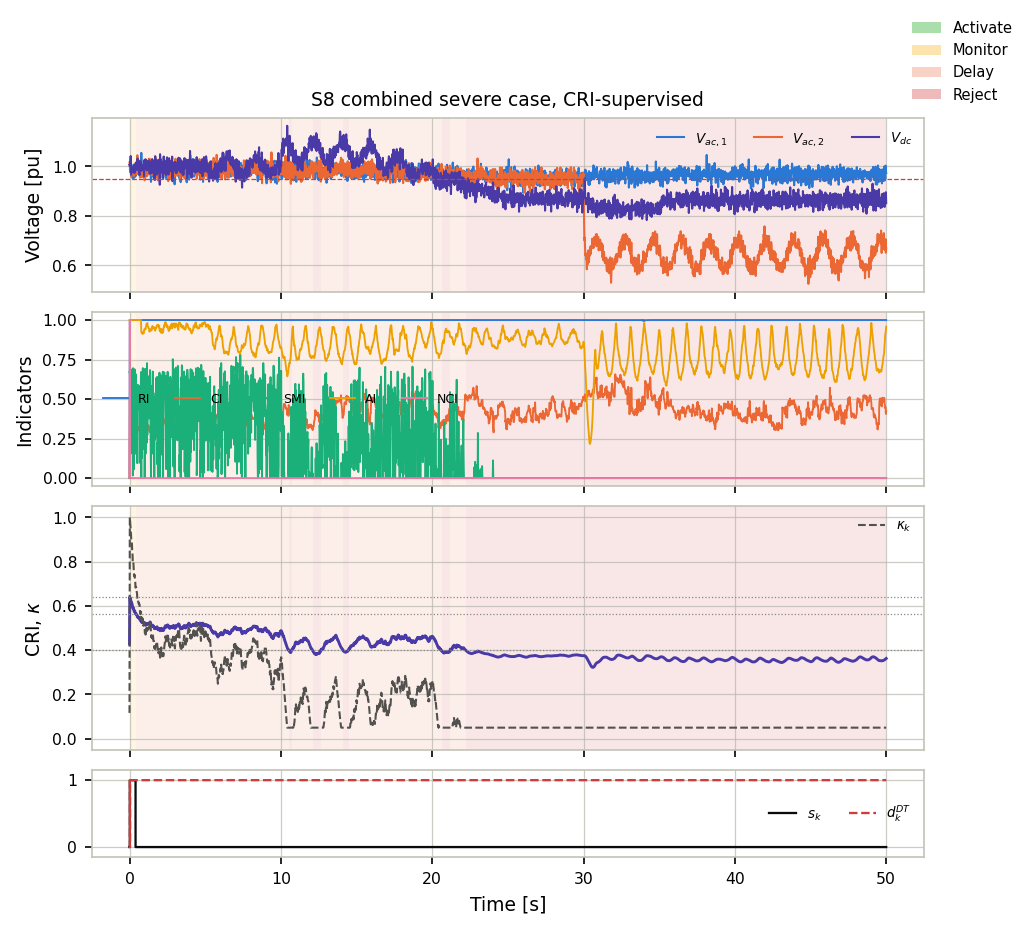

In [4]:
t = log["t"]
fig, axes = plt.subplots(4, 1, figsize=(plotstyle.IEEE_PAGE_WIDTH_IN, 6.4), sharex=True,
                          gridspec_kw=dict(height_ratios=[1, 1, 1.4, 0.5], hspace=0.12))

ax = axes[0]
plotstyle.shade_classification_bg(ax, t, log["cls_code"])
ax.plot(t, log["V1"], color=plotstyle.CAT["blue"], lw=1.0, label="$V_{ac,1}$")
ax.plot(t, log["V2"], color=plotstyle.CAT["orange"], lw=1.0, label="$V_{ac,2}$")
ax.plot(t, log["Vdc"], color=plotstyle.CAT["violet"], lw=1.0, label="$V_{dc}$")
ax.axhline(cons.Vac_min, color=plotstyle.STATUS["Reject"], lw=0.6, ls="--")
ax.set_ylabel("Voltage [pu]"); ax.legend(frameon=False, fontsize=6.5, ncol=3)
ax.set_title("S8 combined severe case, CRI-supervised", fontsize=9)

ax = axes[1]
plotstyle.shade_classification_bg(ax, t, log["cls_code"])
for name in ["RI", "CI", "SMI", "AI", "NCI"]:
    ax.plot(t, log[name], color=plotstyle.INDICATOR_COLORS[name], lw=0.9, label=name)
ax.set_ylabel("Indicators"); ax.set_ylim(-0.05, 1.05); ax.legend(frameon=False, fontsize=6, ncol=5)

ax = axes[2]
plotstyle.shade_classification_bg(ax, t, log["cls_code"])
ax.plot(t, log["CRI"], color=plotstyle.INDICATOR_COLORS["CRI"], lw=1.4)
ax.plot(t, log["kappa"], color=plotstyle.INK_SECONDARY, lw=1.0, ls="--", label=r"$\kappa_k$")
ax.axhline(crip.eta_A, color=plotstyle.INK_MUTED, lw=0.6, ls=":")
ax.axhline(crip.eta_M, color=plotstyle.INK_MUTED, lw=0.6, ls=":")
ax.axhline(crip.eta_D, color=plotstyle.INK_MUTED, lw=0.6, ls=":")
ax.set_ylabel("CRI, $\\kappa$"); ax.set_ylim(-0.05, 1.05); ax.legend(frameon=False, fontsize=6.5)

ax = axes[3]
ax.step(t, log["s"], where="post", color=plotstyle.INK_PRIMARY, lw=1.1, label="$s_k$")
ax.step(t, log["dt_flag"], where="post", color=plotstyle.STATUS["Reject"], lw=1.1, ls="--", label="$d_k^{DT}$")
ax.set_ylim(-0.15, 1.15); ax.set_yticks([0, 1]); ax.set_xlabel("Time [s]")
ax.legend(frameon=False, fontsize=6.5, ncol=2)

handles = plotstyle.classification_legend_handles()
fig.legend(handles=handles, loc="upper right", bbox_to_anchor=(0.995, 0.995), ncol=1, frameon=False, fontsize=7)
plotstyle.savefig(fig, os.path.join(FIG_DIR, "Fig_severe_dashboard.pdf"))
plt.show()

## Figure 10 (v2) -- same run, 2x2 layout, house style

The cell above is kept as the standard reference version (`Fig_severe_dashboard.pdf`, 4 rows
stacked in one column). This condenses the same four panels into a 2x2 grid at double-column
width: (top-left) voltages, (top-right) the five indicators, (bottom-left) CRI and $\kappa_k$
with the decision thresholds, (bottom-right) activation $s_k$ and the digital-twin request flag
$d_k^{DT}$. Same conventions as the other v2 figures: explicit `FIG_WIDTH`/`FIG_HEIGHT`, a
`GRID_*` settings block, per-line style dicts, `LINE_ALPHA=0.98`, no title. Classification
background shading (Activate/Monitor/Delay/Reject) is kept on every panel for context.

C:\Users\asus\AppData\Local\Temp\ipykernel_27832\1549826538.py:210: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=(0, 0, 1, TOP_MARGIN))


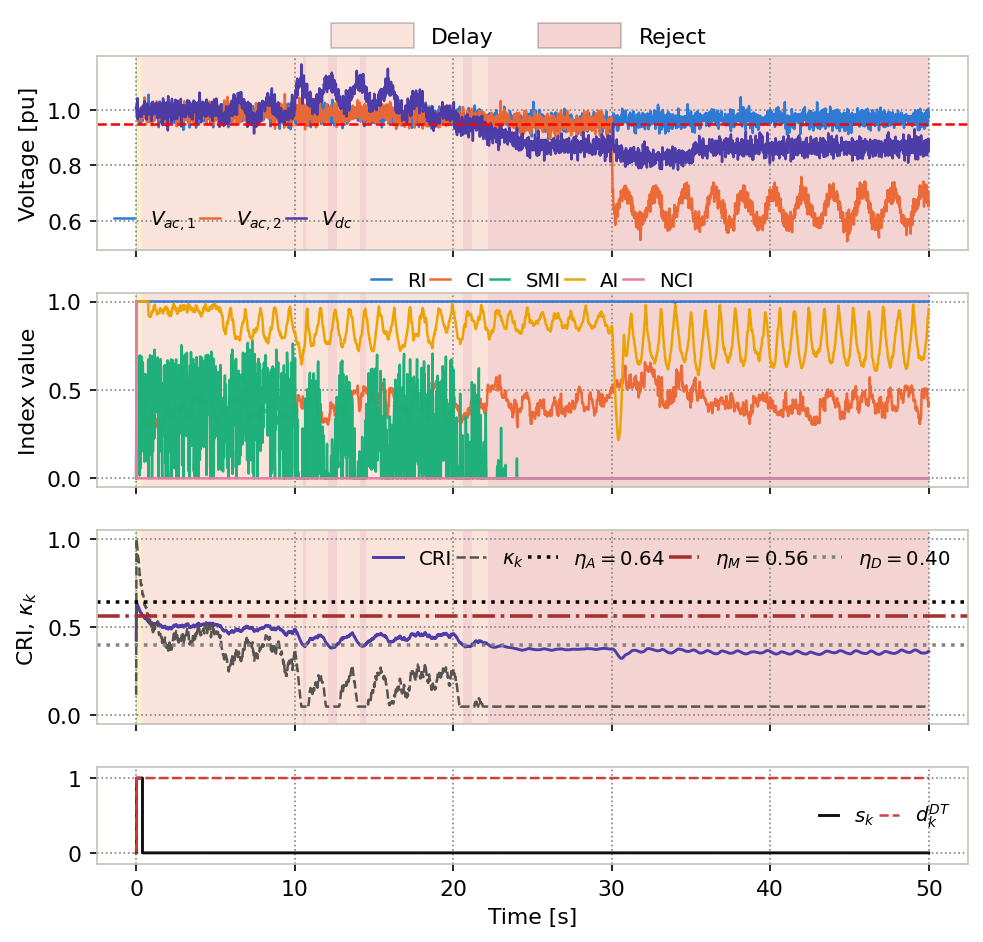

In [5]:
# ======================================================================
# Easy-to-tune figure settings
# ======================================================================

FIG_WIDTH = 7.5
FIG_HEIGHT = 7.0

LINE_ALPHA = 0.98
LW_MAIN = 1.2
LW_LIMIT = 1.2
LW_ETA = 1.7

FONT_AXIS = 10.5
FONT_TICK = 10.5
FONT_LEGEND = 9.5

HEIGHT_RATIOS = [1.0, 1.0, 1.0, 0.5]
HSPACE = 0.25
TOP_MARGIN = 0.93


# ======================================================================
# Legend settings
# ======================================================================

LEGEND_HANDLE_LENGTH = 1
LEGEND_COLUMN_SPACING = 0.2

# Delay ("#ec835a", orange) and Reject ("#d03b3b", red) are distinct
# hues, but plotstyle's default background-shading alpha (0.12) is tuned
# to stay out of the way of dense line data -- at that low opacity both
# wash out to near-identical pale pink and are not distinguishable in the
# plot itself. BG_SHADE_ALPHA raises the actual shading (not just the
# legend swatches) so the two are told apart directly in the figure;
# the legend uses the same value so it matches what is actually shown.
BG_SHADE_ALPHA = 0.22
CLASS_LEGEND_EDGE = "#00000055"


# ======================================================================
# Grid settings
# ======================================================================

GRID_COLOR = "gray"
GRID_ALPHA = 0.98
GRID_LW = 0.80
GRID_LS = ":"


# ======================================================================
# Every line's color + linestyle
# ======================================================================

V_STYLE = {
    "V1": dict(color=plotstyle.CAT["blue"], ls="-", label=r"$V_{ac,1}$"),
    "V2": dict(color=plotstyle.CAT["orange"], ls="-", label=r"$V_{ac,2}$"),
    "Vdc": dict(color=plotstyle.CAT["violet"], ls="-", label=r"$V_{dc}$"),
}

IND_STYLE = {name: dict(color=plotstyle.INDICATOR_COLORS[name], ls="-", label=name)
             for name in ["RI", "CI", "SMI", "AI", "NCI"]}

CRI_STYLE = dict(color=plotstyle.INDICATOR_COLORS["CRI"], ls="-", label="CRI")
KAPPA_STYLE = dict(color=plotstyle.INK_SECONDARY, ls="--", label=r"$\kappa_k$")

ETA_STYLE = {
    "eta_A": dict(value=crip.eta_A, color="black", ls=":", label=rf"$\eta_A={crip.eta_A:.2f}$"),
    "eta_M": dict(value=crip.eta_M, color="brown", ls="-.", label=rf"$\eta_M={crip.eta_M:.2f}$"),
    "eta_D": dict(value=crip.eta_D, color="gray", ls=":", label=rf"$\eta_D={crip.eta_D:.2f}$"),
}

S_STYLE = dict(color=plotstyle.INK_PRIMARY, ls="-", label="$s_k$")
DT_STYLE = dict(color=plotstyle.STATUS["Reject"], ls="--", label=r"$d_k^{DT}$")

LIMIT_COLOR = "red"


# ======================================================================
# Grid helper
# ======================================================================

def style_grid(ax):
    ax.grid(True, color=GRID_COLOR, alpha=GRID_ALPHA, linewidth=GRID_LW, linestyle=GRID_LS)


# ======================================================================
# Classification legend -- limited to the classes actually present and
# visible in this run. cls_code distribution here: Reject 58.9%, Delay
# 40.3%, Monitor 0.7% (too thin to be visible in the shading), Activate
# 0.04% (a single sample at t=0, before the CRI filter starts -- an
# initialization artifact, not a real state). Showing all four (the
# default) would imply Activate/Monitor states that are not actually
# visible anywhere in the plot.
# ======================================================================

from matplotlib.patches import Patch
classification_handles = [
    Patch(facecolor=plotstyle.STATUS["Delay"], alpha=BG_SHADE_ALPHA,
          edgecolor=CLASS_LEGEND_EDGE, linewidth=0.8, label="Delay"),
    Patch(facecolor=plotstyle.STATUS["Reject"], alpha=BG_SHADE_ALPHA,
          edgecolor=CLASS_LEGEND_EDGE, linewidth=0.8, label="Reject"),
]


# ======================================================================
# Data
# ======================================================================

t = log["t"]


# ======================================================================
# Create figure
# ======================================================================

fig, axes = plt.subplots(
    4, 1, figsize=(FIG_WIDTH, FIG_HEIGHT), sharex=True,
    gridspec_kw=dict(height_ratios=HEIGHT_RATIOS, hspace=HSPACE)
)


# ======================================================================
# Row 1: voltages
# ======================================================================

ax = axes[0]
plotstyle.shade_classification_bg(ax, t, log["cls_code"], alpha=BG_SHADE_ALPHA)

for key, style in V_STYLE.items():
    ax.plot(t, log[key], color=style["color"], ls=style["ls"], lw=LW_MAIN,
            alpha=LINE_ALPHA, label=style["label"])
ax.axhline(cons.Vac_min, color=LIMIT_COLOR, lw=LW_LIMIT, ls="--")

ax.set_ylabel("Voltage [pu]", fontsize=FONT_AXIS)
ax.tick_params(labelsize=FONT_TICK)
style_grid(ax)
ax.legend(frameon=False, fontsize=FONT_LEGEND, ncol=3,
          columnspacing=LEGEND_COLUMN_SPACING, handlelength=LEGEND_HANDLE_LENGTH, loc="lower left")


# ======================================================================
# Row 2: the five indicators -- legend placed above this panel (not on
# top of the data) in the gap opened up by the larger HSPACE
# ======================================================================

ax = axes[1]
plotstyle.shade_classification_bg(ax, t, log["cls_code"], alpha=BG_SHADE_ALPHA)

for key, style in IND_STYLE.items():
    ax.plot(t, log[key], color=style["color"], ls=style["ls"], lw=LW_MAIN,
            alpha=LINE_ALPHA, label=style["label"])

ax.set_ylim(-0.05, 1.05)
ax.set_ylabel("Index value", fontsize=FONT_AXIS)
ax.tick_params(labelsize=FONT_TICK)
style_grid(ax)
ax.legend(frameon=False, fontsize=FONT_LEGEND, ncol=5,
          columnspacing=LEGEND_COLUMN_SPACING, handlelength=LEGEND_HANDLE_LENGTH,
          loc="lower center", bbox_to_anchor=(0.5, 0.92))


# ======================================================================
# Row 3: CRI and kappa with decision thresholds -- eta lines drawn
# thicker (LW_ETA) so their legend swatches are readable
# ======================================================================

ax = axes[2]
plotstyle.shade_classification_bg(ax, t, log["cls_code"], alpha=BG_SHADE_ALPHA)

ax.plot(t, log["CRI"], color=CRI_STYLE["color"], ls=CRI_STYLE["ls"], lw=LW_MAIN + 0.2,
        alpha=LINE_ALPHA, label=CRI_STYLE["label"])
ax.plot(t, log["kappa"], color=KAPPA_STYLE["color"], ls=KAPPA_STYLE["ls"], lw=LW_MAIN,
        alpha=LINE_ALPHA, label=KAPPA_STYLE["label"])
for key, style in ETA_STYLE.items():
    ax.axhline(style["value"], color=style["color"], ls=style["ls"], lw=LW_ETA,
               alpha=LINE_ALPHA, label=style["label"])

ax.set_ylim(-0.05, 1.05)
ax.set_ylabel(r"CRI, $\kappa_k$", fontsize=FONT_AXIS)
ax.tick_params(labelsize=FONT_TICK)
style_grid(ax)
ax.legend(frameon=False, fontsize=FONT_LEGEND, ncol=5,
          columnspacing=LEGEND_COLUMN_SPACING, handlelength=LEGEND_HANDLE_LENGTH + 0.5, loc="upper right")


# ======================================================================
# Row 4: activation and digital-twin request flag
# ======================================================================

ax = axes[3]

ax.step(t, log["s"], where="post", color=S_STYLE["color"], ls=S_STYLE["ls"], lw=LW_MAIN + 0.2,
        alpha=LINE_ALPHA, label=S_STYLE["label"])
ax.step(t, log["dt_flag"], where="post", color=DT_STYLE["color"], ls=DT_STYLE["ls"], lw=LW_MAIN,
        alpha=LINE_ALPHA, label=DT_STYLE["label"])

ax.set_ylim(-0.15, 1.15)
ax.set_yticks([0, 1])
ax.set_xlabel("Time [s]", fontsize=FONT_AXIS)
ax.tick_params(labelsize=FONT_TICK)
style_grid(ax)
ax.legend(frameon=False, fontsize=FONT_LEGEND, ncol=2,
          columnspacing=LEGEND_COLUMN_SPACING, handlelength=LEGEND_HANDLE_LENGTH, loc="center right")


# ======================================================================
# Shared classification legend (Delay/Reject only -- see note above)
# ======================================================================

fig.tight_layout(rect=(0, 0, 1, TOP_MARGIN))
fig.legend(handles=classification_handles, loc="upper center", bbox_to_anchor=(0.5, 0.93), ncol=2,
           frameon=False, fontsize=FONT_LEGEND + 1.0, handlelength=3.8, handleheight=1.4)


# ======================================================================
# Save and display
# ======================================================================

fig.savefig(os.path.join(FIG_DIR, "Fig_severe_dashboard_v2.pdf"), format="pdf", bbox_inches="tight")
plt.show()

C:\Users\asus\AppData\Local\Temp\ipykernel_27832\3505687593.py:538: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(


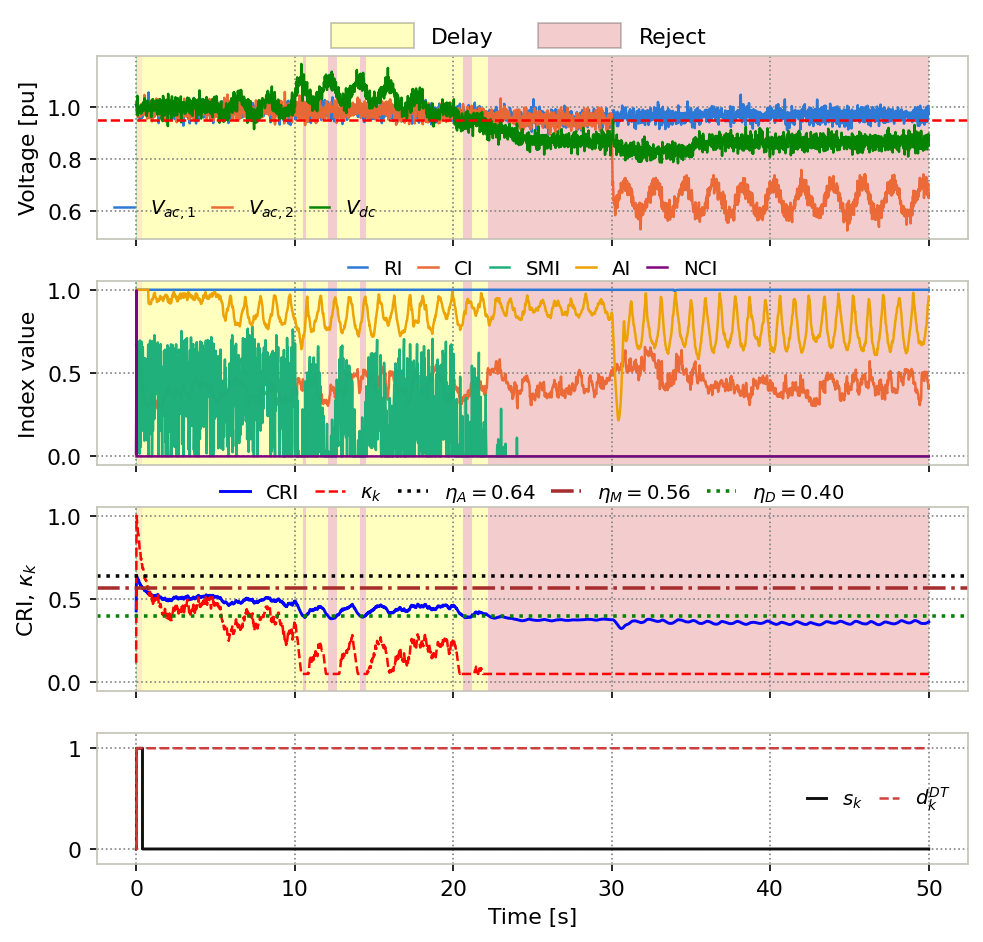

In [7]:
# ======================================================================
# Easy-to-tune figure settings
# ======================================================================

FIG_WIDTH = 7.5
FIG_HEIGHT = 7.0

LINE_ALPHA = 0.98

LW_MAIN = 1.2
LW_LIMIT = 1.2
LW_ETA = 1.7

FONT_AXIS = 10.5
FONT_TICK = 10.5
FONT_LEGEND = 9.5

HEIGHT_RATIOS = [0.7, 0.7, 0.7, 0.5]

HSPACE = 0.25
TOP_MARGIN = 0.93


# ======================================================================
# Easy-to-change colors
# ======================================================================

# Row 1: voltages
COLOR_V1 = plotstyle.CAT["blue"]
COLOR_V2 = plotstyle.CAT["orange"]
COLOR_VDC = plotstyle.CAT["green"] 

# Row 2: indicators
COLOR_RI  = plotstyle.INDICATOR_COLORS["RI"]
COLOR_CI  = plotstyle.INDICATOR_COLORS["CI"]
COLOR_SMI = plotstyle.INDICATOR_COLORS["SMI"]
COLOR_AI  = plotstyle.INDICATOR_COLORS["AI"]
COLOR_NCI = "purple"

# Row 3: CRI, kappa, eta thresholds
COLOR_CRI = "blue"
COLOR_KAPPA = "red"

COLOR_ETA_A = "black"
COLOR_ETA_M = "brown"
COLOR_ETA_D = "green"

# Row 4
COLOR_S = plotstyle.INK_PRIMARY
COLOR_DT = plotstyle.STATUS["Reject"]

# Operational limit
LIMIT_COLOR = "red"


# ======================================================================
# Delay / Reject colors and shading
# ======================================================================

# These keep the CURRENT plotstyle colors by default.
# You can replace them with "orange", "red", "#EC835A", etc.
DELAY_COLOR = "yellow"
REJECT_COLOR = plotstyle.STATUS["Reject"]

# Common alpha for the background classification shading
BG_SHADE_ALPHA = 0.25

# Legend edge around Delay / Reject patches
CLASS_LEGEND_EDGE = "#00000055"


# ======================================================================
# Legend settings
# ======================================================================

LEGEND_HANDLE_LENGTH = 1.0
LEGEND_COLUMN_SPACING = 0.8


# ======================================================================
# Grid settings
# ======================================================================

GRID_COLOR = "gray"
GRID_ALPHA = 0.98
GRID_LW = 0.80
GRID_LS = ":"


# ======================================================================
# Every line's color + linestyle
# ======================================================================

V_STYLE = {

    "V1": dict(
        color=COLOR_V1,
        ls="-",
        label=r"$V_{ac,1}$"
    ),

    "V2": dict(
        color=COLOR_V2,
        ls="-",
        label=r"$V_{ac,2}$"
    ),

    "Vdc": dict(
        color=COLOR_VDC,
        ls="-",
        label=r"$V_{dc}$"
    ),
}


IND_STYLE = {

    "RI": dict(
        color=COLOR_RI,
        ls="-",
        label="RI"
    ),

    "CI": dict(
        color=COLOR_CI,
        ls="-",
        label="CI"
    ),

    "SMI": dict(
        color=COLOR_SMI,
        ls="-",
        label="SMI"
    ),

    "AI": dict(
        color=COLOR_AI,
        ls="-",
        label="AI"
    ),

    "NCI": dict(
        color=COLOR_NCI,
        ls="-",
        label="NCI"
    ),
}


CRI_STYLE = dict(
    color=COLOR_CRI,
    ls="-",
    label="CRI"
)


KAPPA_STYLE = dict(
    color=COLOR_KAPPA,
    ls="--",
    label=r"$\kappa_k$"
)


ETA_STYLE = {

    "eta_A": dict(
        value=crip.eta_A,
        color=COLOR_ETA_A,
        ls=":",
        label=rf"$\eta_A={crip.eta_A:.2f}$"
    ),

    "eta_M": dict(
        value=crip.eta_M,
        color=COLOR_ETA_M,
        ls="-.",
        label=rf"$\eta_M={crip.eta_M:.2f}$"
    ),

    "eta_D": dict(
        value=crip.eta_D,
        color=COLOR_ETA_D,
        ls=":",
        label=rf"$\eta_D={crip.eta_D:.2f}$"
    ),
}


S_STYLE = dict(
    color=COLOR_S,
    ls="-",
    label=r"$s_k$"
)


DT_STYLE = dict(
    color=COLOR_DT,
    ls="--",
    label=r"$d_k^{DT}$"
)


# ======================================================================
# Grid helper
# ======================================================================

def style_grid(ax):

    ax.grid(
        True,
        color=GRID_COLOR,
        alpha=GRID_ALPHA,
        linewidth=GRID_LW,
        linestyle=GRID_LS
    )


# ======================================================================
# Classification legend
# ======================================================================

from matplotlib.patches import Patch


classification_handles = [

    Patch(
        facecolor=DELAY_COLOR,
        alpha=BG_SHADE_ALPHA,
        edgecolor=CLASS_LEGEND_EDGE,
        linewidth=0.8,
        label="Delay"
    ),

    Patch(
        facecolor=REJECT_COLOR,
        alpha=BG_SHADE_ALPHA,
        edgecolor=CLASS_LEGEND_EDGE,
        linewidth=0.8,
        label="Reject"
    ),
]


# ======================================================================
# Data
# ======================================================================

t = log["t"]


# ======================================================================
# IMPORTANT:
# Temporarily replace the STATUS colors used by
# plotstyle.shade_classification_bg()
#
# This keeps your existing plotstyle shading function exactly as before,
# while allowing DELAY_COLOR and REJECT_COLOR above to control the colors.
# ======================================================================

_original_delay_color = plotstyle.STATUS["Delay"]
_original_reject_color = plotstyle.STATUS["Reject"]

plotstyle.STATUS["Delay"] = DELAY_COLOR
plotstyle.STATUS["Reject"] = REJECT_COLOR


# ======================================================================
# Create figure
# ======================================================================

fig, axes = plt.subplots(
    4,
    1,
    figsize=(FIG_WIDTH, FIG_HEIGHT),
    sharex=True,
    gridspec_kw=dict(
        height_ratios=HEIGHT_RATIOS,
        hspace=HSPACE
    )
)


# ======================================================================
# Row 1: voltages
# ======================================================================

ax = axes[0]

plotstyle.shade_classification_bg(
    ax,
    t,
    log["cls_code"],
    alpha=BG_SHADE_ALPHA
)


for key, style in V_STYLE.items():

    ax.plot(
        t,
        log[key],
        color=style["color"],
        ls=style["ls"],
        lw=LW_MAIN,
        alpha=LINE_ALPHA,
        label=style["label"]
    )


ax.axhline(
    cons.Vac_min,
    color=LIMIT_COLOR,
    lw=LW_LIMIT,
    ls="--"
)


ax.set_ylabel(
    "Voltage [pu]",
    fontsize=FONT_AXIS
)

ax.tick_params(
    labelsize=FONT_TICK
)

style_grid(ax)


ax.legend(
    frameon=False,
    fontsize=FONT_LEGEND,
    ncol=3,
    columnspacing=LEGEND_COLUMN_SPACING,
    handlelength=LEGEND_HANDLE_LENGTH,
    loc="lower left"
)


# ======================================================================
# Row 2: five indicators
# ======================================================================

ax = axes[1]

plotstyle.shade_classification_bg(
    ax,
    t,
    log["cls_code"],
    alpha=BG_SHADE_ALPHA
)


for key, style in IND_STYLE.items():

    ax.plot(
        t,
        log[key],
        color=style["color"],
        ls=style["ls"],
        lw=LW_MAIN,
        alpha=LINE_ALPHA,
        label=style["label"]
    )


ax.set_ylim(
    -0.05,
    1.05
)

ax.set_ylabel(
    "Index value",
    fontsize=FONT_AXIS
)

ax.tick_params(
    labelsize=FONT_TICK
)

style_grid(ax)


ax.legend(
    frameon=False,
    fontsize=FONT_LEGEND,
    ncol=5,
    columnspacing=LEGEND_COLUMN_SPACING,
    handlelength=LEGEND_HANDLE_LENGTH,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.92)
)


# ======================================================================
# Row 3: CRI and kappa with decision thresholds
# ======================================================================

ax = axes[2]

plotstyle.shade_classification_bg(
    ax,
    t,
    log["cls_code"],
    alpha=BG_SHADE_ALPHA
)


ax.plot(
    t,
    log["CRI"],
    color=CRI_STYLE["color"],
    ls=CRI_STYLE["ls"],
    lw=LW_MAIN + 0.2,
    alpha=LINE_ALPHA,
    label=CRI_STYLE["label"]
)


ax.plot(
    t,
    log["kappa"],
    color=KAPPA_STYLE["color"],
    ls=KAPPA_STYLE["ls"],
    lw=LW_MAIN,
    alpha=LINE_ALPHA,
    label=KAPPA_STYLE["label"]
)


for key, style in ETA_STYLE.items():

    ax.axhline(
        style["value"],
        color=style["color"],
        ls=style["ls"],
        lw=LW_ETA,
        alpha=LINE_ALPHA,
        label=style["label"]
    )


ax.set_ylim(
    -0.05,
    1.05
)

ax.set_ylabel(
    r"CRI, $\kappa_k$",
    fontsize=FONT_AXIS
)

ax.tick_params(
    labelsize=FONT_TICK
)

style_grid(ax)


ax.legend(
    frameon=False,
    fontsize=FONT_LEGEND,
    ncol=5,
    columnspacing=LEGEND_COLUMN_SPACING,
    handlelength=LEGEND_HANDLE_LENGTH + 0.5,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.92)
)


# ======================================================================
# Row 4: activation and digital-twin request flag
# ======================================================================

ax = axes[3]


ax.step(
    t,
    log["s"],
    where="post",
    color=S_STYLE["color"],
    ls=S_STYLE["ls"],
    lw=LW_MAIN + 0.2,
    alpha=LINE_ALPHA,
    label=S_STYLE["label"]
)


ax.step(
    t,
    log["dt_flag"],
    where="post",
    color=DT_STYLE["color"],
    ls=DT_STYLE["ls"],
    lw=LW_MAIN,
    alpha=LINE_ALPHA,
    label=DT_STYLE["label"]
)


ax.set_ylim(
    -0.15,
    1.15
)

ax.set_yticks(
    [0, 1]
)

ax.set_xlabel(
    "Time [s]",
    fontsize=FONT_AXIS
)

ax.tick_params(
    labelsize=FONT_TICK
)

style_grid(ax)


ax.legend(
    frameon=False,
    fontsize=FONT_LEGEND,
    ncol=2,
    columnspacing=LEGEND_COLUMN_SPACING,
    handlelength=LEGEND_HANDLE_LENGTH,
    loc="center right"
)


# ======================================================================
# Shared classification legend
# ======================================================================

fig.tight_layout(
    rect=(0, 0, 1, TOP_MARGIN)
)


fig.legend(
    handles=classification_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.93),
    ncol=2,
    frameon=False,
    fontsize=FONT_LEGEND + 1.0,
    handlelength=3.8,
    handleheight=1.4
)


# ======================================================================
# Restore original plotstyle colors
# ======================================================================

plotstyle.STATUS["Delay"] = _original_delay_color
plotstyle.STATUS["Reject"] = _original_reject_color


# ======================================================================
# Save and display
# ======================================================================

fig.savefig(
    os.path.join(
        FIG_DIR,
        "Fig_severe_dashboard_v2.pdf"
    ),
    format="pdf",
    bbox_inches="tight"
)

plt.show()

## Strategy comparison table

In [5]:
rows = []
for strategy, lg in logs.items():
    z = validation.compute_unsafe_truth(lg, cons, noise_level_pct=scenario.noise_cfg.get("level_pct", 0.0))
    rows.append(dict(
        strategy=strategy,
        E_V=metrics.voltage_deviation(lg["V1"], lg["V2"], pp.Vac_nom),
        E_dc=metrics.dc_voltage_deviation(lg["Vdc"], pp.Vdc_nom),
        violation_pct=metrics.violation_duration_pct(lg["V1"], lg["V2"], lg["I1"], lg["I2"], lg["Vdc"], cons),
        N_FA=metrics.false_activation_count(lg["s"], z),
        unsafe_active_fraction=metrics.unsafe_active_fraction(lg["s"], z),
        safe_availability_pct=metrics.safe_availability_pct(lg["s"], z),
        T_on_s=metrics.active_duration(lg["s"], pp.Ts),
        DT_requests=int(np.sum(lg["dt_flag"])) if strategy == "cri" else np.nan,
    ))
summary = pd.DataFrame(rows).set_index("strategy")
display(summary.round(4))
summary.to_csv(os.path.join(RESULTS_DIR, "results_S8_strategy_summary.csv"))

,E_V,E_dc,violation_pct,N_FA,unsafe_active_fraction,safe_availability_pct,T_on_s,DT_requests
strategy,,,,,,,,
direct,0.1559,0.1974,79.5282,2501,1.0000,NaN,50.02,NaN
threshold,0.1663,0.0987,66.6134,835,0.3339,NaN,16.70,NaN
cri,0.1688,0.0924,64.5742,19,0.0076,NaN,0.38,2500.0


In [6]:
cols = ["t", "RI", "CI", "SMI", "AI", "NCI", "CRI", "kappa", "s", "cls_code", "dt_flag",
        "V1", "V2", "Vdc", "I1", "I2"]
df = pd.DataFrame({c: log[c] for c in cols})
df.to_csv(os.path.join(RESULTS_DIR, "results_S8.csv"), index=False)
print("Saved", len(df), "rows to results_S8.csv")

Saved 2501 rows to results_S8.csv


## Takeaway

Under the combined severe case, the CRI-supervised strategy drives `s_k` to 0 and keeps it
there, scales `kappa_k` down, and raises the digital-twin request flag -- while Direct activation
drives the plant through large, sustained constraint violations and even the simple hard-limit
threshold rule only partially protects the system. This is the stress test the safety claim of
the paper rests on.